# 02 - Exploratory Data Analysis
**Proyek:** Rental Price Predictor & Deal Spotter - Kos di Kota Depok

Notebook ini menjawab pertanyaan bisnis berikut dari `listings_clean.csv`:

| # | Pertanyaan |
|---|---|
| 1 | Kecamatan mana yang paling mahal, dan berapa selisihnya setelah komposisi fasilitas disamakan? |
| 2 | Berapa premium harga AC dan kamar mandi dalam? |
| 3 | Fasilitas mana yang paling terkait dengan harga? *(bahan matriks Power BI)* |
| 4 | Kenapa jarak ke UI nyaris tidak berkorelasi dengan harga? Apakah titik acuannya kurang tepat? |
| 5 | Seberapa besar selisih harga antara listing segar dan basi? |
| 6 | Bagaimana pengaruh tipe kos (putra/putri/campur) dan luas kamar? |

**Cara membaca angka.** *Mentah* = perbandingan langsung (median/rata-rata). *Terkontrol* = efek setelah menyamakan faktor lain lewat regresi OLS pada `log(harga)` dengan *robust standard error* (HC3); koefisien diubah menjadi persen. Hubungan terkontrol tetap **asosiasi, bukan sebab-akibat**: kualitas yang tidak terukur (kondisi bangunan, foto, lingkungan) tetap tercampur.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold"})

# --- Lokasi file (otomatis: lokal atau Kaggle) ---
KAGGLE = Path("/kaggle/working").exists()
CANDIDATES = [Path("../data/processed/listings_clean.csv"), Path("/kaggle/working/listings_clean.csv")]
if Path("/kaggle/input").exists():
    CANDIDATES += list(Path("/kaggle/input").glob("**/listings_clean.csv"))
CLEAN = next((p for p in CANDIDATES if p.exists()), None)
assert CLEAN is not None, "listings_clean.csv tidak ditemukan. Jalankan 01_cleaning dulu / tambahkan sebagai input."
OUT_DIR = Path("/kaggle/working") if KAGGLE else CLEAN.parent
FIG_DIR = Path("/kaggle/working/figures") if KAGGLE else Path("../docs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("Data:", CLEAN, "| Output:", OUT_DIR, "| Gambar:", FIG_DIR)

def save(name): plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

ModuleNotFoundError: No module named 'scipy'

In [ ]:
df = pd.read_csv(CLEAN, parse_dates=["updated_at", "scraped_at"])
fac = [c for c in df.columns if c.startswith("f_")]
FAC_LABEL = {"f_ac": "AC", "f_kipas_angin": "Kipas angin", "f_kasur": "Kasur", "f_lemari": "Lemari", "f_meja": "Meja",
             "f_kursi": "Kursi", "f_tv": "TV", "f_kulkas": "Kulkas", "f_wifi": "WiFi", "f_km_dalam": "K. mandi dalam",
             "f_km_luar": "K. mandi luar", "f_air_panas": "Air panas", "f_shower": "Shower", "f_kloset_duduk": "Kloset duduk",
             "f_dapur": "Dapur", "f_cctv": "CCTV", "f_pengurus_penjaga": "Pengurus/penjaga", "f_laundry_cuci": "Laundry/cuci",
             "f_parkir_mobil": "Parkir mobil", "f_cleaning_service": "Cleaning service", "f_jendela": "Jendela"}

df["dekat_ui"] = (df["jarak_ui_km"] <= 1).astype(int)
df["km_cat"] = np.where(df["f_km_dalam"] == 1, "dalam", np.where(df["f_km_luar"] == 1, "luar saja", "tak tercatat"))
d = df.dropna(subset=["luas_m2"]).copy()          # baris dengan luas valid, untuk model yang memakai luas

FAC_TERMS = " + ".join(fac)
FAC_NO_KM = " + ".join(f for f in fac if f not in ("f_km_dalam", "f_km_luar"))
BASE = "C(kecamatan) + C(tipe_kos) + luas_m2 + jarak_ui_km + jarak_krl_km + is_fresh"

def pct(b): return (np.exp(b) - 1) * 100
def fit(formula, data): return smf.ols(formula, data=data).fit(cov_type="HC3")
def effect(m, term):
    ci = m.conf_int().loc[term]
    return pct(m.params[term]), pct(ci[0]), pct(ci[1]), m.pvalues[term]
def boot_median_diff(a, b, n=2000, seed=42):
    rng = np.random.default_rng(seed); a, b = np.asarray(a), np.asarray(b)
    diffs = [np.median(rng.choice(a, len(a))) - np.median(rng.choice(b, len(b))) for _ in range(n)]
    return np.median(a) - np.median(b), np.percentile(diffs, 2.5), np.percentile(diffs, 97.5)
def rp(x): return f"Rp {x/1e6:,.2f} jt"

print(df.shape, "| dengan luas valid:", len(d))

(2059, 59) | dengan luas valid: 2037


## 1. Gambaran umum harga

count       2059.0
mean     1146833.0
std       504003.0
min       300000.0
25%       750000.0
50%      1000000.0
75%      1500000.0
max      5000000.0
Skewness harga: 1.52 | skewness log(harga): 0.25


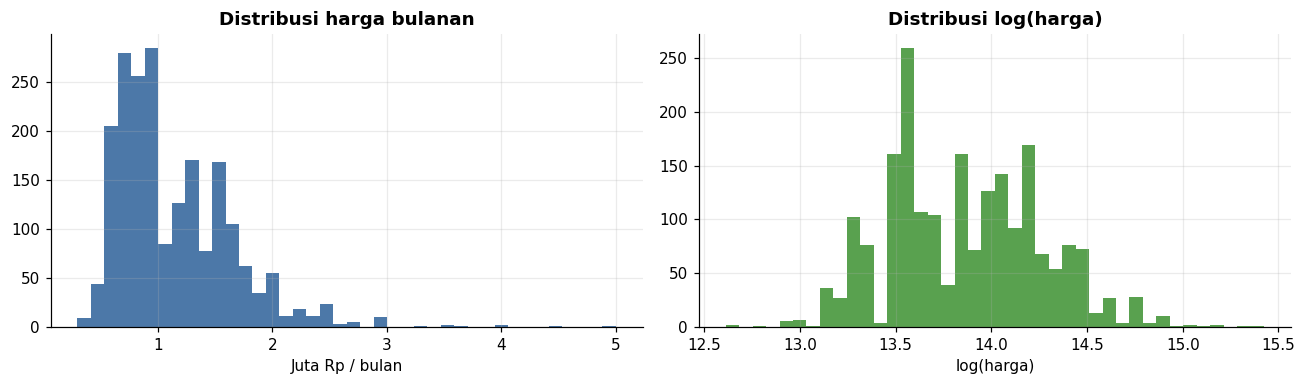

In [ ]:
print(df["harga_bulanan"].describe().round(0).to_string())
print("Skewness harga:", round(stats.skew(df["harga_bulanan"]), 2), "| skewness log(harga):", round(stats.skew(df["log_harga"]), 2))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(df["harga_bulanan"] / 1e6, bins=40, color="#4c78a8"); ax[0].set_title("Distribusi harga bulanan"); ax[0].set_xlabel("Juta Rp / bulan")
ax[1].hist(df["log_harga"], bins=40, color="#59a14f"); ax[1].set_title("Distribusi log(harga)"); ax[1].set_xlabel("log(harga)")
plt.tight_layout(); save("01_distribusi_harga"); plt.show()

### Peringatan *data leakage*: `kelas_harga` / `is_eksklusif`
Kolom ini kelihatannya fitur biasa, padahal kemungkinan besar turunan dari harga itu sendiri. Cek di bawah ini.

In [ ]:
print(df.groupby("kelas_harga")["harga_bulanan"].agg(["count", "min", "median", "max"]).to_string())
acc = ((df["harga_bulanan"] >= 1_000_000) == (df["kelas_harga"] == "eksklusif")).mean()
print(f"\nAturan sederhana 'harga >= Rp 1 jt = eksklusif' cocok dengan label pada {acc:.1%} listing")

             count     min     median      max
kelas_harga                                   
eksklusif     1204  400000  1350000.0  5000000
murah          855  300000   750000.0   999000

Aturan sederhana 'harga >= Rp 1 jt = eksklusif' cocok dengan label pada 96.2% listing


**Temuan:** semua listing `murah` berharga di bawah Rp 1 jt dan aturan "harga ≥ Rp 1 jt = eksklusif" cocok pada 96,2% listing. Jadi `kelas_harga` dan `is_eksklusif` pada dasarnya adalah **label hasil harga**. **Jangan dipakai sebagai fitur** di model (juga tidak sebagai variabel kontrol di EDA ini), karena model akan "mengintip" jawabannya.

## 2. Harga per kecamatan
Pertanyaan: kecamatan mana yang paling mahal, dan apakah selisihnya tetap ada setelah AC, kamar mandi, tipe, dan luas disamakan? Basis pembanding adalah **Beji** (kecamatan dengan data terbanyak).

,n,median,rata2,pct_ac,pct_km_dalam,jarak_ui_median
kecamatan,,,,,,
Cinere,262,1255000.0,1304898.85,0.52,0.65,5.68
Sukmajaya,137,1100000.0,1207072.99,0.46,0.63,3.89
Beji,856,1000500.0,1170136.12,0.47,0.80,1.14
Tapos,76,1000000.0,1067434.21,0.41,0.72,8.02
Limo,112,1000000.0,1119223.21,0.51,0.68,5.75
Cimanggis,256,950000.0,1101482.80,0.39,0.75,2.78
Cilodong,54,925000.0,1007870.37,0.31,0.67,6.89
Pancoran Mas,130,900000.0,1037730.77,0.28,0.70,4.56
Cipayung,24,900000.0,1025000.00,0.17,0.75,7.77


Uji Kruskal-Wallis antar kecamatan: p = 4.70e-12


,pct,lo,hi,p,n
Cinere,13.05,9.16,17.08,0.00,262
Sukmajaya,1.60,-3.30,6.75,0.53,137
Cipayung,0.78,-11.47,14.72,0.91,24
Bojongsari,0.44,-5.81,7.10,0.89,79
Limo,0.06,-4.56,4.91,0.98,112
Pancoran Mas,-0.56,-5.41,4.54,0.83,130
Cimanggis,-2.25,-5.66,1.29,0.21,256
Sawangan,-4.65,-11.26,2.45,0.19,73
Cilodong,-7.18,-14.13,0.32,0.06,54
Tapos,-9.33,-15.52,-2.68,0.01,76


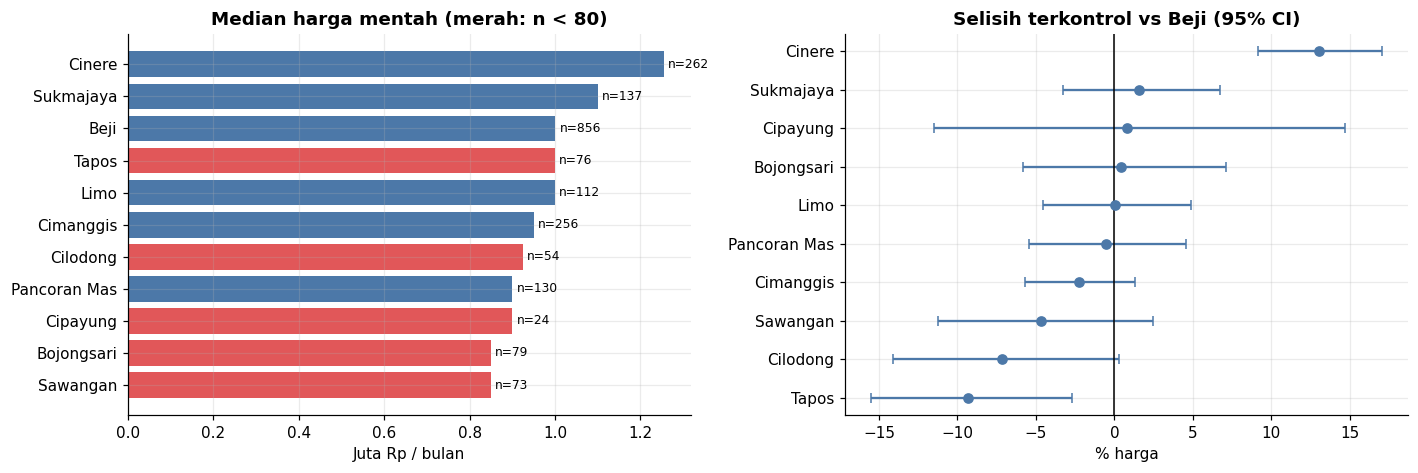

In [ ]:
kec = (df.groupby("kecamatan").agg(n=("id", "count"), median=("harga_bulanan", "median"), rata2=("harga_bulanan", "mean"),
                                     pct_ac=("f_ac", "mean"), pct_km_dalam=("f_km_dalam", "mean"),
                                     jarak_ui_median=("jarak_ui_km", "median"))
       .sort_values("median", ascending=False))
display(kec.round(2))
print("Uji Kruskal-Wallis antar kecamatan: p =", f"{stats.kruskal(*[g.harga_bulanan.values for _, g in df.groupby('kecamatan')]).pvalue:.2e}")

m_kec = fit(f'log_harga ~ C(kecamatan, Treatment("Beji")) + C(tipe_kos) + luas_m2 + is_fresh + {FAC_TERMS}', d)
rows = {k: effect(m_kec, f'C(kecamatan, Treatment("Beji"))[T.{k}]') for k in kec.index if k != "Beji"}
adj = pd.DataFrame(rows, index=["pct", "lo", "hi", "p"]).T.join(kec["n"]).sort_values("pct", ascending=False)
display(adj.round(2))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
colors = ["#e15759" if n < 80 else "#4c78a8" for n in kec["n"]]
ax[0].barh(kec.index[::-1], kec["median"][::-1] / 1e6, color=colors[::-1])
for i, (k, r) in enumerate(kec[::-1].iterrows()): ax[0].text(r["median"] / 1e6 + .01, i, f"n={int(r['n'])}", va="center", fontsize=8)
ax[0].set_title("Median harga mentah (merah: n < 80)"); ax[0].set_xlabel("Juta Rp / bulan")
a2 = adj[::-1]
ax[1].errorbar(a2["pct"], range(len(a2)), xerr=[a2["pct"] - a2["lo"], a2["hi"] - a2["pct"]], fmt="o", color="#4c78a8", capsize=3)
ax[1].axvline(0, color="k", lw=1); ax[1].set_yticks(range(len(a2))); ax[1].set_yticklabels(a2.index)
ax[1].set_title("Selisih terkontrol vs Beji (95% CI)"); ax[1].set_xlabel("% harga")
plt.tight_layout(); save("02_harga_per_kecamatan"); plt.show()

**Temuan**
- Harga memang berbeda antar kecamatan (Kruskal-Wallis p ≈ 5·10⁻¹²). Median mentah tertinggi: **Cinere (Rp 1,26 jt)**, Sukmajaya (Rp 1,10 jt), lalu Beji (Rp 1,00 jt). Terendah: Sawangan dan Bojongsari (Rp 850 rb). Jadi Beji **bukan** yang termahal.
- Setelah AC, kamar mandi, dan fasilitas lain disamakan, **sebagian besar selisih mentah menyusut**. Sawangan (-4,7%) dan Bojongsari (+0,4%) tidak bisa dibedakan dari Beji secara statistik. Selisih mentahnya terutama karena komposisi: kos ber-AC hanya 22-24% di dua kecamatan itu vs 47% di Beji.
- Dua perbedaan yang bertahan: **Cinere +13%** dibanding Beji (CI 9 sampai 17%) dan **Tapos -9%** (CI -16 sampai -3%, tetapi n hanya 76). Cilodong (-7%) mendekati batas signifikan dengan n = 54.
- Cipayung (n = 24) tidak bisa disimpulkan: rentang kepastiannya sangat lebar.

**Catatan:** kontrol di bagian ini tidak menyertakan jarak ke UI/KRL, karena lokasi justru yang sedang dibandingkan. Kelebihan harga Cinere konsisten dengan temuan di bagian 5 (harga sedikit naik ke arah barat laut), tetapi penyebabnya belum diuji.

## 3. Premium AC dan kamar mandi dalam
Tiga tingkat perbandingan: **mentah**, **terkontrol dasar** (kecamatan, tipe, luas, jarak, kesegaran), dan **terkontrol penuh** (ditambah semua fasilitas lain).

In [ ]:
def premium(var):
    a, b = df[df[var] == 1]["harga_bulanan"], df[df[var] == 0]["harga_bulanan"]
    diff, lo, hi = boot_median_diff(a, b)
    m1 = fit(f"log_harga ~ {var} + {BASE}", d)
    others = " + ".join(f for f in fac if f != var)
    m2 = fit(f"log_harga ~ {var} + {BASE} + {others}", d)
    e1, e2 = effect(m1, var), effect(m2, var)
    return {"n_ada": len(a), "n_tidak": len(b), "median_ada": a.median(), "median_tidak": b.median(),
            "selisih_median": diff, "ci_lo": lo, "ci_hi": hi,
            "mentah_%": (a.median() / b.median() - 1) * 100,
            "dasar_%": e1[0], "dasar_ci": f"{e1[1]:+.1f}..{e1[2]:+.1f}",
            "penuh_%": e2[0], "penuh_ci": f"{e2[1]:+.1f}..{e2[2]:+.1f}"}

pm = pd.DataFrame({"AC": premium("f_ac"), "K. mandi dalam": premium("f_km_dalam")}).T
display(pm.round(1))

,n_ada,n_tidak,median_ada,median_tidak,selisih_median,ci_lo,ci_hi,mentah_%,dasar_%,dasar_ci,penuh_%,penuh_ci
AC,884,1175,1500000.0,800000.0,700000.0,600000.0,700000.0,87.5,79.162346,+75.0..+83.4,54.851929,+50.3..+59.6
K. mandi dalam,1506,553,1100000.0,850000.0,250000.0,250000.0,400000.0,29.411765,22.898858,+18.2..+27.7,7.836245,+3.8..+12.1


km_cat
dalam           1506
luar saja        445
tak tercatat     108 

Dalam vs luar-saja: median Rp 1.10 jt vs Rp 0.80 jt | selisih Rp 0.30 jt (CI Rp 0.25 jt..Rp 0.40 jt) | terkontrol penuh +12.2% (CI +8.8..+15.7)

Median harga: AC x kamar mandi dalam


median            count     
f_km_dalam          0          1     0    1
f_ac                                       
0            750000.0   800000.0   402  773
1           1300000.0  1500000.0   151  733

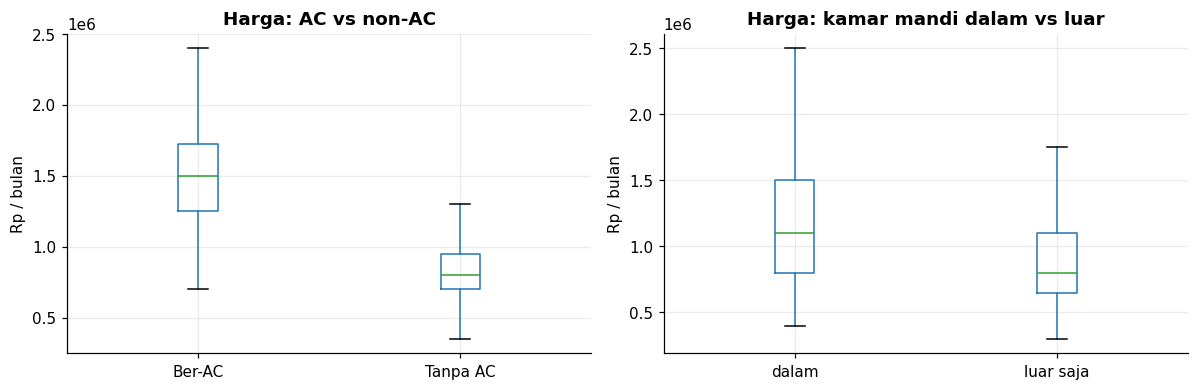

In [ ]:
# Kamar mandi dalam vs LUAR (bukan "non-dalam", karena 108 listing tidak mencatat kamar mandi sama sekali)
print(df["km_cat"].value_counts().to_string(), "\n")
s = d[d["km_cat"].isin(["dalam", "luar saja"])].copy(); s["dalam"] = (s["km_cat"] == "dalam").astype(int)
a, b = s[s.dalam == 1]["harga_bulanan"], s[s.dalam == 0]["harga_bulanan"]
diff, lo, hi = boot_median_diff(a, b)
m = fit(f"log_harga ~ dalam + {BASE} + {FAC_NO_KM}", s)
e = effect(m, "dalam")
print(f"Dalam vs luar-saja: median {rp(a.median())} vs {rp(b.median())} | selisih {rp(diff)} (CI {rp(lo)}..{rp(hi)}) | terkontrol penuh {e[0]:+.1f}% (CI {e[1]:+.1f}..{e[2]:+.1f})")

print("\nMedian harga: AC x kamar mandi dalam")
display(df.pivot_table(index="f_ac", columns="f_km_dalam", values="harga_bulanan", aggfunc=["median", "count"]).round(0))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
df.assign(AC=df.f_ac.map({0: "Tanpa AC", 1: "Ber-AC"})).boxplot(column="harga_bulanan", by="AC", ax=ax[0], showfliers=False)
df[df.km_cat != "tak tercatat"].boxplot(column="harga_bulanan", by="km_cat", ax=ax[1], showfliers=False)
for a_, t in zip(ax, ["Harga: AC vs non-AC", "Harga: kamar mandi dalam vs luar"]): a_.set_title(t); a_.set_xlabel(""); a_.set_ylabel("Rp / bulan")
plt.suptitle(""); plt.tight_layout(); save("03_premium_ac_km"); plt.show()

**Temuan**
- **AC:** median Rp 1,5 jt vs Rp 0,8 jt (selisih Rp 0,7 jt, CI Rp 0,6 sampai 0,7 jt; +88% mentah). Setelah kecamatan, tipe, luas, jarak, dan kesegaran disamakan, premium AC sekitar **+79%**; setelah semua fasilitas lain ikut dikontrol, sekitar **+55%** (CI 50 sampai 60%). Angka ini tetap sangat besar karena AC menjadi penanda "kelas" kos (kualitas bangunan yang tidak terukur ikut terbawa), jadi baca sebagai **batas atas** hubungan, bukan efek sebab-akibat.
- **Kamar mandi dalam vs luar:** median Rp 1,1 jt vs Rp 0,8 jt (selisih Rp 0,3 jt). Terkontrol penuh **+12%** (CI 9 sampai 16%). Perbandingan "dalam vs non-dalam" memberi angka lebih kecil (+8%) karena kelompok non-dalam berisi 108 listing yang tidak mencatat kamar mandi.
- **Tabel AC x kamar mandi dalam** menunjukkan AC sebagai penggerak utama: tanpa AC, kamar mandi dalam hanya menambah ±Rp 50 rb (750 rb → 800 rb); dengan AC, selisihnya Rp 200 rb (1,3 jt → 1,5 jt). Melompat dari tanpa-AC ke ber-AC menambah Rp 550 sampai 700 rb.

## 4. Fasilitas mana yang paling terkait dengan harga?
Dua sudut pandang: **mentah** (median harga ada vs tidak ada) dan **terkontrol** (efek tiap fasilitas setelah semua fasilitas lain, kecamatan, tipe, luas, jarak, dan kesegaran disamakan dalam satu model). Hasil terkontrol diekspor ke `facility_premium.csv` untuk matriks fasilitas di Power BI.

In [ ]:
m_fac = fit(f"log_harga ~ {FAC_TERMS} + {BASE}", d)
rows = []
for f in fac:
    e = effect(m_fac, f); a, b = df[df[f] == 1]["harga_bulanan"], df[df[f] == 0]["harga_bulanan"]
    rows.append({"fasilitas": FAC_LABEL[f], "kode": f, "persen_listing": df[f].mean() * 100, "median_ada": a.median(), "median_tidak": b.median(),
                 "premium_mentah_pct": (a.median() / b.median() - 1) * 100, "premium_terkontrol_pct": e[0],
                 "ci_bawah": e[1], "ci_atas": e[2], "p_value": e[3]})
ft = pd.DataFrame(rows).sort_values("premium_terkontrol_pct", ascending=False).reset_index(drop=True)
ft["signifikan"] = np.where(ft["p_value"] < .05, "ya", "tidak")
display(ft.drop(columns="kode").round(2))
print("R-kuadrat model:", round(m_fac.rsquared, 3))
ft.to_csv(OUT_DIR / "facility_premium.csv", index=False, encoding="utf-8")

g = ft[::-1]
fig, ax = plt.subplots(figsize=(8, 7))
col = np.where(g["p_value"] < .05, "#2e7d32", "#9e9e9e")
ax.errorbar(g["premium_terkontrol_pct"], range(len(g)), xerr=[g["premium_terkontrol_pct"] - g["ci_bawah"], g["ci_atas"] - g["premium_terkontrol_pct"]], fmt="none", ecolor="#bdbdbd", capsize=2)
ax.scatter(g["premium_terkontrol_pct"], range(len(g)), c=col, zorder=3)
ax.axvline(0, color="k", lw=1); ax.set_yticks(range(len(g))); ax.set_yticklabels(g["fasilitas"])
ax.set_title("Premium harga terkontrol per fasilitas (95% CI)\nhijau: signifikan (p < 0,05)"); ax.set_xlabel("% perubahan harga")
plt.tight_layout(); save("04_premium_fasilitas"); plt.show()

In [ ]:
# Fasilitas yang saling berkaitan: koefisien individu perlu dibaca hati-hati
cm = df[fac].corr().abs().where(~np.eye(len(fac), dtype=bool)).stack()
cm = cm[[i[0] < i[1] for i in cm.index]].sort_values(ascending=False).head(6)
cm.index = [f"{FAC_LABEL[a]} - {FAC_LABEL[b]}" for a, b in cm.index]
cm.round(2).rename("korelasi")

**Temuan (terkontrol, model R² = 0,64)**
- **AC** jauh di atas yang lain (**+55%**). Berikutnya: **air panas +13,6%**, **parkir mobil +8,5%**, **shower +8,1%**, **kamar mandi dalam +7,8%**, **kloset duduk +6,5%**, **dapur +5,7%**, **cleaning service +4,5%**, dan **kursi +3,4%**. Semuanya signifikan pada p < 0,05.
- **Fasilitas yang tampak mahal tetapi sebenarnya hanya penanda:** WiFi punya premium mentah +41% tetapi hanya **+2,3%** (tidak signifikan) setelah dikontrol. Hal serupa terjadi pada kulkas, CCTV, TV, dan laundry. Fasilitas ini banyak dimiliki kos yang memang sudah bagus, tapi tidak mendongkrak harga sendirian.
- **Kamar mandi luar** berasosiasi dengan harga lebih rendah (-3,8%). **Kasur** (-5,6%) dan pengurus/penjaga (-2,2%) berada di batas signifikan (p ≈ 0,06): jangan ditafsirkan sebagai "kasur menurunkan harga".

**Peringatan:** beberapa fasilitas saling berkaitan erat (kasur-lemari 0,71; kursi-meja 0,71; kamar mandi dalam-luar 0,62), jadi koefisien individualnya tidak stabil. Untuk memilah kontribusi tiap fasilitas di model, SHAP pada model pohon di `03_modeling` lebih tepat. Hasil di atas diekspor ke `facility_premium.csv` untuk matriks fasilitas di Power BI.

## 5. Jarak ke UI dan stasiun KRL
Korelasi keseluruhan hampir nol. Ada tiga penjelasan yang diuji satu per satu: (a) pengaruhnya hanya ada di zona dekat kampus, (b) pengaruhnya hilang setelah komposisi fasilitas disamakan, dan (c) titik acuan UI kurang tepat atau polanya bukan radial.

In [ ]:
rho_ui = stats.spearmanr(df.jarak_ui_km, df.harga_bulanan)[0]; rho_krl = stats.spearmanr(df.jarak_krl_km, df.harga_bulanan)[0]
print(f"Spearman harga~jarak UI: {rho_ui:+.3f} | harga~jarak KRL terdekat: {rho_krl:+.3f}")

edges = [0, .5, 1, 1.5, 2, 3, 5, 8, 20]
bt = df.assign(zona=pd.cut(df.jarak_ui_km, edges)).groupby("zona", observed=True)["harga_bulanan"].agg(n="count", median="median", q25=lambda x: x.quantile(.25), q75=lambda x: x.quantile(.75))
display(bt.round(0))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
hb = ax[0].hexbin(df.jarak_ui_km, df.harga_bulanan / 1e6, gridsize=30, bins="log", mincnt=1, cmap="Blues")
ax[0].plot([i.mid for i in bt.index], bt["median"] / 1e6, "o-", color="#e15759", label="median per zona"); ax[0].set_ylim(0, 4); ax[0].legend()
ax[0].set_xlabel("Jarak ke UI (km)"); ax[0].set_ylabel("Juta Rp / bulan"); ax[0].set_title("Harga vs jarak ke UI")
sp = {k: stats.spearmanr(g.jarak_ui_km, g.harga_bulanan)[0] for k, g in df.groupby("kecamatan") if len(g) >= 70}
sp = pd.Series(sp).sort_values()
ax[1].barh(sp.index, sp.values, color=np.where(sp.values < 0, "#4c78a8", "#e15759")); ax[1].axvline(0, color="k", lw=1)
ax[1].set_title("Korelasi harga~jarak UI per kecamatan (n >= 70)"); ax[1].set_xlabel("Spearman")
plt.tight_layout(); save("05_jarak_ui"); plt.show()

**(a) Zona dekat kampus (≤ 1 km) dan (b) kontrol komposisi.**

In [ ]:
a, b = df[df.dekat_ui == 1]["harga_bulanan"], df[df.dekat_ui == 0]["harga_bulanan"]
diff, lo, hi = boot_median_diff(a, b)
print(f"MENTAH   : median <=1 km {rp(a.median())} vs >1 km {rp(b.median())} | selisih {rp(diff)} (CI {rp(lo)}..{rp(hi)}) | n = {len(a)} vs {len(b)}")
m = fit(f"log_harga ~ dekat_ui + C(kecamatan) + C(tipe_kos) + luas_m2 + is_fresh + {FAC_TERMS}", d)
e = effect(m, "dekat_ui"); print(f"TERKONTROL: premium <=1 km = {e[0]:+.1f}% (CI {e[1]:+.1f}..{e[2]:+.1f}, p = {e[3]:.2f})")

comp = df.groupby("dekat_ui").agg(n=("id", "count"), pct_ac=("f_ac", "mean"), pct_km_dalam=("f_km_dalam", "mean"), rata2_fasilitas=("n_fasilitas", "mean"),
                                  pct_putri=("tipe_kos", lambda s: (s == "putri").mean()), pct_segar=("is_fresh", "mean"))
comp.index = comp.index.map({0: "> 1 km", 1: "<= 1 km"}); display(comp.round(2))

**(c) Apakah titik acuan UI kurang tepat?** Kita geser titik pusat di grid sekitar 15 x 15 km di sekitar UI dan hitung korelasi harga~jarak untuk tiap titik. Kalau UI titik yang tepat, korelasi terkuatnya harus berada di dekat UI.

In [ ]:
UI = (-6.3624, 106.8272)
def hav(a1, o1, a2, o2):
    p1, p2 = np.radians(a1), np.radians(a2); dl = np.radians(o2 - o1)
    x = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(x))
lats = np.linspace(UI[0] - .07, UI[0] + .07, 21); lons = np.linspace(UI[1] - .07, UI[1] + .07, 21)
R = np.array([[stats.spearmanr(hav(df.latitude, df.longitude, la, lo), df.harga_bulanan)[0] for lo in lons] for la in lats])
i, j = np.unravel_index(R.argmin(), R.shape)
print(f"Korelasi di titik UI           : {rho_ui:+.3f}")
print(f"Korelasi terkuat (negatif) grid : {R.min():+.3f} di ({lats[i]:.4f}, {lons[j]:.4f}) = {hav(*UI, lats[i], lons[j]):.1f} km dari UI")
print(f"Korelasi harga~lintang: {stats.spearmanr(df.latitude, df.harga_bulanan)[0]:+.3f} | harga~bujur: {stats.spearmanr(df.longitude, df.harga_bulanan)[0]:+.3f}")

fig, ax = plt.subplots(figsize=(6.2, 5))
im = ax.pcolormesh(lons, lats, R, cmap="RdBu", vmin=-.3, vmax=.3, shading="auto"); plt.colorbar(im, label="Spearman harga~jarak")
ax.plot(UI[1], UI[0], "k*", ms=14, label="UI (titik acuan)"); ax.plot(lons[j], lats[i], "g^", ms=10, label="korelasi terkuat"); ax.legend(loc="lower left")
ax.set_xticks(lons[::4]); ax.set_xticklabels([f"{x:.2f}" for x in lons[::4]]); ax.set_xlabel("Bujur"); ax.set_ylabel("Lintang"); ax.set_title("Seberapa 'tepat' titik pusat?")
plt.tight_layout(); save("06_uji_titik_acuan"); plt.show()

In [ ]:
# KRL: apakah dekat stasiun menaikkan harga?
bk = df.assign(zona=pd.cut(df.jarak_krl_km, [0, 1, 2, 3, 5, 8, 20])).groupby("zona", observed=True)["harga_bulanan"].agg(n="count", median="median")
display(bk.round(0))
m = fit(f"log_harga ~ jarak_krl_km + jarak_ui_km + C(kecamatan) + C(tipe_kos) + luas_m2 + is_fresh + {FAC_TERMS}", d)
e = effect(m, "jarak_krl_km"); print(f"Tiap +1 km dari stasiun KRL terdekat (terkontrol): {e[0]:+.1f}% (CI {e[1]:+.1f}..{e[2]:+.1f}, p = {e[3]:.3f})")

**Temuan: jarak ke UI bukan penentu harga di Depok, dan pola harga bukan radial dari UI.**
- **(a) Zona dekat kampus:** premium mentah ada. Median Rp 1,2 jt untuk ≤ 1 km (318 listing) vs Rp 1,0 jt untuk jarak yang lebih jauh. Tapi di luar 1 km, median **datar di Rp 0,95 sampai 1,0 jt** pada semua zona sampai 20 km. Tidak ada kurva menurun yang mulus.
- **(b) Setelah komposisi disamakan, premiumnya hilang:** +0,4% (CI -2,9 sampai +3,8%, p = 0,82). Kos dalam radius 1 km lebih lengkap: AC 53% vs 41%, kamar mandi dalam 84% vs 71%, kos putri 50% vs 42%. Jadi harga yang lebih tinggi menempel pada *isi* kos. *Nuansa:* kalau kedekatan kampus membuat pemilik memasang AC lebih sering, efek tidak langsung itu ikut terhapus oleh kontrol fasilitas dan tidak bisa dipisahkan di data ini.
- **(c) Titik acuan:** korelasi harga~jarak paling kuat justru terjadi untuk titik sekitar **3,5 km di barat laut UI**, di antara pusat kecamatan Cinere dan Limo (ρ ≈ -0,17), bukan di UI (ρ = -0,02). Itu stabil walaupun area pencarian diperbesar. Jadi titik UI memang bukan pusat "gravitasi" harga, tetapi korelasi terbaiknya pun masih lemah. Harga cenderung sedikit naik ke arah utara-barat (korelasi dengan lintang +0,11), searah wilayah Jakarta; itu hipotesis, belum diuji. Korelasi per kecamatan juga tidak konsisten arahnya (Sukmajaya -0,17, tetapi Cimanggis +0,13 dan Tapos +0,15).
- **KRL:** setiap +1 km dari stasiun terdekat malah berasosiasi dengan harga **+2,4%** (CI +0,5 sampai +4,3%), arah yang berlawanan dari dugaan. Kemungkinan penyebabnya: daftar stasiun yang dipakai hanya empat stasiun di Depok tengah, dan kawasan mahal seperti Cinere dan Limo memang tidak dilewati jalur KRL.

**Implikasi:** jarak ke UI dan KRL sebaiknya jadi fitur tambahan, bukan fitur utama. Biarkan model pohon belajar dari koordinat (lat/lon) dan kecamatan. Titik acuan dan daftar stasiun masih perlu diverifikasi di Google Maps.

## 6. Listing segar vs basi
Listing dianggap **segar** bila `updated_at` ≤ 365 hari sebelum scraping. Pertanyaan: apakah harga di listing basi berbeda, dan apakah perbedaan itu karena harganya usang atau karena isinya memang berbeda?

In [ ]:
g = df.groupby("is_fresh")["harga_bulanan"].agg(n="count", median="median", rata2="mean")
g.index = g.index.map({0: "basi", 1: "segar"}); display(g.round(0))
a, b = df[df.is_fresh == 1]["harga_bulanan"], df[df.is_fresh == 0]["harga_bulanan"]
diff, lo, hi = boot_median_diff(a, b)
print(f"Selisih median segar - basi: {rp(diff)} (CI {rp(lo)}..{rp(hi)}) | Mann-Whitney p = {stats.mannwhitneyu(a, b).pvalue:.1e}")

print("\nKomposisi: apa yang berbeda antara segar dan basi?")
comp = df.groupby("is_fresh").agg(pct_ac=("f_ac", "mean"), pct_km_dalam=("f_km_dalam", "mean"), rata2_fasilitas=("n_fasilitas", "mean"),
                                  median_luas=("luas_m2", "median"), pct_putri=("tipe_kos", lambda s: (s == "putri").mean()))
comp.index = comp.index.map({0: "basi", 1: "segar"}); display(comp.round(2))

m = fit(f"log_harga ~ is_fresh + C(kecamatan) + C(tipe_kos) + luas_m2 + {FAC_TERMS}", d)
e = effect(m, "is_fresh"); print(f"\nTERKONTROL: listing segar vs basi = {e[0]:+.1f}% (CI {e[1]:+.1f}..{e[2]:+.1f}, p = {e[3]:.3f})")

yr = df.assign(tahun=df.updated_at.dt.year).groupby("tahun").agg(n=("id", "count"), median=("harga_bulanan", "median"), pct_ac=("f_ac", "mean"), rata2_fasilitas=("n_fasilitas", "mean"))
yr = yr[yr.n >= 10]; display(yr.round(2))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
df.assign(k=df.is_fresh.map({0: "Basi", 1: "Segar"})).boxplot(column="harga_bulanan", by="k", ax=ax[0], showfliers=False); ax[0].set_title("Harga: segar vs basi"); ax[0].set_xlabel("")
ax[1].bar(yr.index.astype(str), yr["median"] / 1e6, color="#4c78a8"); ax[1].set_title("Median harga menurut tahun update terakhir"); ax[1].set_ylabel("Juta Rp"); ax[1].set_ylim(0, 1.4)
plt.suptitle(""); plt.tight_layout(); save("07_segar_vs_basi"); plt.show()

**Temuan: selisih harga segar vs basi ada, tetapi bukan karena harga basi "ketinggalan zaman".**
- **Mentah:** median listing segar Rp 1,1 jt vs basi Rp 1,0 jt (selisih Rp 0,1 jt, CI Rp 0,05 sampai 0,2 jt; rata-rata Rp 1,17 jt vs 1,12 jt, sekitar +4%).
- **Penyebabnya komposisi:** listing segar lebih lengkap (rata-rata 22 vs 18 fasilitas), lebih sering ber-AC (49% vs 36%), dan lebih sering berkamar mandi dalam (79% vs 67%). Median harga menurut tahun update naik dari Rp 0,95 jt (2021) menjadi Rp 1,1 jt (2026), searah dengan jumlah fasilitas (14 → 22).
- **Terkontrol:** setelah komposisi disamakan, listing segar justru sekitar **2,5% lebih murah** (CI -4,7 sampai -0,3%). Selisihnya kecil dan borderline, jadi tidak ada bukti bahwa listing basi berharga lebih rendah secara sistematis.

**Implikasi untuk modeling:** pertahankan listing basi (jangan dibuang), tetapi masukkan `is_fresh` atau `umur_update_hari` sebagai fitur. Di `03_modeling`, bandingkan MAE model dengan semua listing vs hanya yang segar, dan laporkan hasilnya di README.

## 7. Tipe kos dan luas kamar

In [ ]:
t = df.groupby("tipe_kos").agg(n=("id", "count"), median=("harga_bulanan", "median"), rata2=("harga_bulanan", "mean"), pct_ac=("f_ac", "mean"), median_luas=("luas_m2", "median"))
display(t.round(2))
m = fit(f'log_harga ~ C(tipe_kos, Treatment("campur")) + C(kecamatan) + luas_m2 + jarak_ui_km + is_fresh + {FAC_TERMS}', d)
for k in ["putra", "putri"]:
    e = effect(m, f'C(tipe_kos, Treatment("campur"))[T.{k}]'); print(f"{k} vs campur (terkontrol): {e[0]:+.1f}% (CI {e[1]:+.1f}..{e[2]:+.1f}, p = {e[3]:.3f})")

lb = d.assign(luas=pd.cut(d.luas_m2, [0, 6, 9, 12, 16, 24, 40])).groupby("luas", observed=True)["harga_bulanan"].agg(n="count", median="median"); display(lb.round(0))
m = fit(f"log_harga ~ luas_m2 + C(kecamatan) + C(tipe_kos) + is_fresh + {FAC_TERMS}", d)
e = effect(m, "luas_m2"); print(f"Tiap +1 m2 luas (terkontrol): {e[0]:+.2f}% (CI {e[1]:+.2f}..{e[2]:+.2f})")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(t.index, t["median"] / 1e6, color=["#4c78a8", "#f28e2b", "#e15759"]); ax[0].set_title("Median harga per tipe kos"); ax[0].set_ylabel("Juta Rp")
ax[1].bar([str(i) for i in lb.index], lb["median"] / 1e6, color="#59a14f"); ax[1].set_title("Median harga menurut luas kamar (m²)"); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); save("08_tipe_luas"); plt.show()

**Temuan**
- **Tipe kos:** median mentah putri (Rp 1,1 jt) > campur (Rp 1,0 jt) > putra (Rp 850 rb). Tapi setelah fasilitas disamakan, **putra -8%** dan **putri -6%** dibanding campur. Kos putri tampak mahal terutama karena lebih sering ber-AC (51% vs 36-37%).
- **Luas kamar:** tiap +1 m² berasosiasi dengan **+0,8%** harga (CI 0,6 sampai 1,1%). Hubungannya tidak linear: median naik sampai kisaran 12-16 m² (Rp 1,2 jt), lalu datar di Rp 1,1 jt untuk kamar yang lebih besar. Luas bukan penggerak harga yang kuat dibanding fasilitas.

## 8. Rangkuman dan implikasi untuk modeling

### Rangkuman temuan
1. **Fasilitas mengalahkan lokasi.** AC adalah penggerak harga terbesar (+55% terkontrol), disusul air panas, parkir mobil, shower, dan kamar mandi dalam.
2. **Lokasi bekerja lewat kawasan, bukan jarak ke UI.** Cinere +13% dibanding Beji setelah komposisi disamakan, sementara premium dekat UI hilang setelah fasilitas disamakan.
3. **Gap antar kecamatan sebagian besar adalah gap komposisi** (terutama persentase kos ber-AC), bukan lokasi murni.
4. **Listing basi tidak lebih murah secara sistematis**, hanya isinya lebih sederhana.
5. **WiFi dan CCTV adalah penanda kos yang sudah bagus**, bukan pendongkrak harga sendiri.

### Implikasi untuk `03_modeling`
- **Jangan pakai** `kelas_harga` / `is_eksklusif` (data leakage), dan jangan pakai kolom harga harian/mingguan/tahunan.
- **Fitur utama:** AC, air panas, parkir mobil, shower, kamar mandi dalam/luar, kloset duduk, dapur, luas, tipe kos, kecamatan, serta lat/lon. Jarak ke UI/KRL dan flag ≤ 1 km sebagai fitur tambahan.
- **Baseline pembanding:** median harga per kecamatan, dibandingkan dengan Random Forest / Gradient Boosting (cross-validation, laporkan MAE dan MAPE).
- **Pertahankan listing basi**, tambahkan `is_fresh` / `umur_update_hari`, dan bandingkan MAE dengan/tanpa listing basi.
- **Fasilitas saling berkorelasi:** pakai model pohon + SHAP untuk menilai kontribusi fasilitas, bukan koefisien regresi individual.
- **Data tipis:** Cipayung (24) dan Cilodong (54) perlu ditandai di hasil per kecamatan.

### Keterbatasan
- Semua temuan adalah **asosiasi**, bukan sebab-akibat; kualitas yang tidak terukur (kondisi bangunan, foto, lingkungan) tidak ada di data.
- Data adalah **harga listing** pada satu waktu (scraping 19 Oktober 2026), bukan harga transaksi.
- Banyak uji dijalankan sekaligus, jadi p-value yang dekat 0,05 sebaiknya dibaca hati-hati.
- Titik acuan UI dan stasiun KRL berupa koordinat perkiraan; luas kamar dari teks bebas, dengan 22 listing yang dikosongkan karena tidak valid atau tidak terparse.